Praktikum 3 - Seleksi fitur, label encoding, dan standardisasi.

Input: Titanic-Dataset-fixed.csv (hasil imputasi praktikum 2).
Output: tabel ter-encode + terstandardisasi di output/.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("encoding_scaling.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js02-pemahaman-data-dan-pra-pengolahan-data\praktikum-3


In [2]:
from pathlib import Path

import matplotlib

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler

BASE = Path(__file__).resolve().parent
DATA = BASE.parent / "data" / "Titanic-Dataset-fixed.csv"
OUT = BASE / "output"
OUT.mkdir(parents=True, exist_ok=True)

In [3]:
# ---------- Langkah 1-2: load + slice fitur ----------
df = pd.read_csv(DATA)
print("=== Data awal ===", df.shape)
fitur = ["Survived", "Pclass", "Age", "Sex", "Cabin"]
df = df[fitur].copy()
print("=== Setelah seleksi fitur ===", df.shape)
print(df.head().to_string())

=== Data awal === (891, 12)
=== Setelah seleksi fitur === (891, 5)
   Survived  Pclass   Age     Sex Cabin
0         0       3  22.0    male  DECK
1         1       1  38.0  female   C85
2         1       3  26.0  female  DECK
3         1       1  35.0  female  C123
4         0       3  35.0    male  DECK


In [4]:
# ---------- Langkah 3: label encoding ----------
le = LabelEncoder()
for col in ["Sex", "Cabin"]:
    df[col] = le.fit_transform(df[col])
    mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    if len(mapping) > 6:  # Cabin punya 148 nilai unik, cukup ringkas
        contoh = {k: int(mapping[k]) for k in list(mapping)[:3] + ["DECK"] if k in mapping}
        print(f"\nMapping {col}: {len(mapping)} kategori, contoh {contoh}")
    else:
        print(f"\nMapping {col}: { {k: int(v) for k, v in mapping.items()} }")

print("\n=== Setelah encoding ===")
print(df.head().to_string())


Mapping Sex: {'female': 0, 'male': 1}

Mapping Cabin: 148 kategori, contoh {'A10': 0, 'A14': 1, 'A16': 2, 'DECK': 115}

=== Setelah encoding ===
   Survived  Pclass   Age  Sex  Cabin
0         0       3  22.0    1    115
1         1       1  38.0    0     81
2         1       3  26.0    0    115
3         1       1  35.0    0     55
4         0       3  35.0    1    115


In [5]:
# ---------- Langkah 5: standardisasi Age ----------
age_sebelum = df["Age"].describe()
std = StandardScaler()
df["Age"] = std.fit_transform(df[["Age"]])
print(f"\nStandardScaler: mean_={std.mean_[0]:.4f} scale_(std populasi)={std.scale_[0]:.4f}")


StandardScaler: mean_=29.6991 scale_(std populasi)=12.9947



=== Age sebelum vs sesudah standardisasi ===
      sebelum  sesudah
mean  29.6991   0.0000
std   13.0020   1.0006
min    0.4200  -2.2532
max   80.0000   3.8709
cek: mean~0 -> True, std~1 -> True

5 data teratas hasil akhir:
    Survived  Pclass       Age  Sex  Cabin
0         0       3 -0.592481    1    115
1         1       1  0.638789    0     81
2         1       3 -0.284663    0    115
3         1       1  0.407926    0     55
4         0       3  0.407926    1    115

Dimensi akhir: (891, 5) | missing: 0


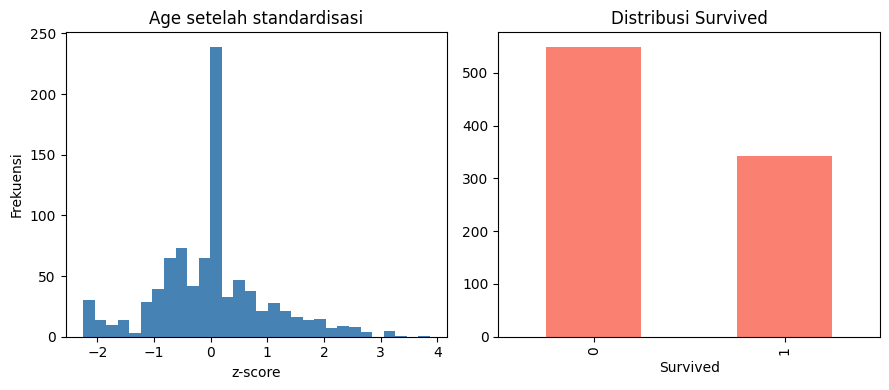

In [6]:
# ---------- Langkah 6: verifikasi ----------
print("\n=== Age sebelum vs sesudah standardisasi ===")
cek = pd.DataFrame({
    "sebelum": age_sebelum[["mean", "std", "min", "max"]],
    "sesudah": df["Age"].describe()[["mean", "std", "min", "max"]],
})
print(cek.round(4).to_string())
print(f"cek: mean~0 -> {abs(df['Age'].mean()) < 1e-9}, std~1 -> {abs(df['Age'].std(ddof=0) - 1) < 1e-9}")
print("\n5 data teratas hasil akhir:\n", df.head().to_string())
print("\nDimensi akhir:", df.shape, "| missing:", int(df.isnull().sum().sum()))

df.to_csv(OUT / "titanic_prat3_encoded_scaled.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].hist(df["Age"], bins=30, color="steelblue")
axes[0].set_title("Age setelah standardisasi")
axes[0].set_xlabel("z-score")
axes[0].set_ylabel("Frekuensi")
df["Survived"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="salmon")
axes[1].set_title("Distribusi Survived")
axes[1].set_xlabel("Survived")
fig.tight_layout()
fig.savefig(OUT / "verifikasi_encoding_scaling.png", dpi=110)